# Life Expectancy

The dataset from Worldometer provides a ranked list of countries based on life expectancy at birth, which represents the average number of years a newborn is expected to live under current mortality rates. It includes global, regional, and country-specific life expectancy figures, with separate data for males and females. The dataset highlights disparities in longevity across nations, with countries like Hong Kong, Japan, and South Korea having the highest life expectancies. This data serves as a key indicator of public health, quality of life, and healthcare effectiveness, offering valuable insights for policymakers, researchers, and global health organizations.

In [25]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

df = pd.read_csv("life_expectancy.csv")
df.head()

,Country,Sum of Females Life Expectancy,Sum of Life Expectancy (both sexes),Sum of Males Life Expectancy
0,Chad,57.19,55.24,53.36
1,Nigeria,54.94,54.64,54.33
2,South Sudan,60.75,57.74,54.76
3,Lesotho,60.44,57.80,55.03
4,Central African Republic,59.56,57.67,55.51


In [26]:
df.shape

(200, 4)

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Country                               200 non-null    object 
 1   Sum of Females  Life Expectancy       200 non-null    float64
 2   Sum of Life Expectancy  (both sexes)  200 non-null    float64
 3   Sum of Males  Life Expectancy         200 non-null    float64
dtypes: float64(3), object(1)
memory usage: 6.4+ KB


In [28]:
df.describe()

,Sum of Females Life Expectancy,Sum of Life Expectancy (both sexes),Sum of Males Life Expectancy
count,200.000000,200.000000,200.000000
mean,76.776900,74.133700,71.517200
std,8.820332,8.571318,8.419633
min,54.940000,54.640000,53.360000
25%,71.300000,68.732500,66.270000
50%,77.955000,74.700000,71.250000
75%,81.985000,79.062500,76.565000
max,149.220000,143.280000,137.640000


In [29]:
df = df.rename(columns={
    "Sum of Females  Life Expectancy": "female",
    "Sum of Males  Life Expectancy": "male",
    "Sum of Life Expectancy  (both sexes)": "both",
})

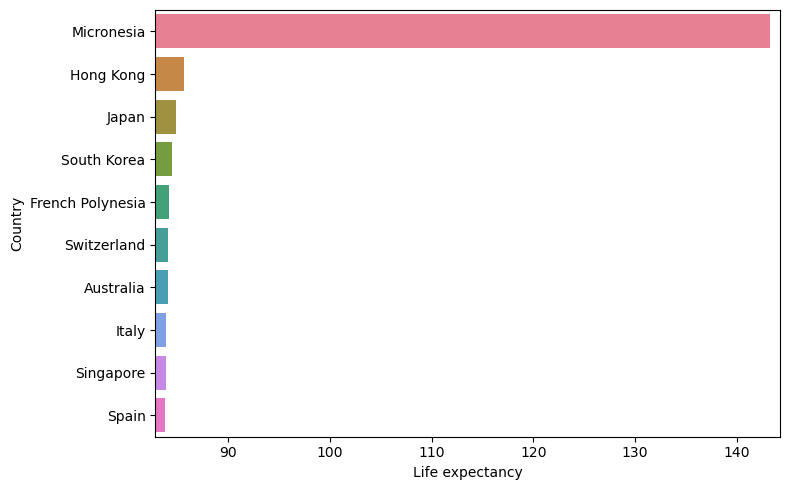

In [30]:
top = df.nlargest(10, "both")

plt.figure(figsize=(8, 5))
sns.barplot(data=top, x="both", y="Country", hue="Country", palette="husl", legend=False, dodge=False)
plt.xlim(top["both"].min() - 1, top["both"].max() + 1)
plt.xlabel("Life expectancy")
plt.tight_layout()
plt.show()

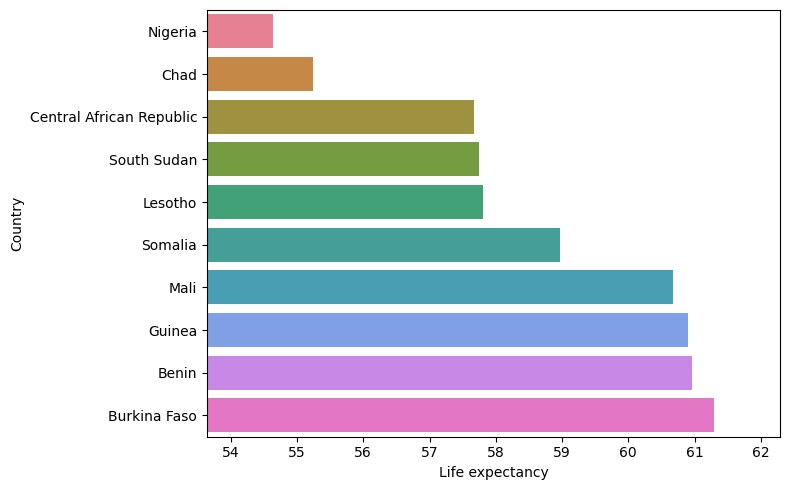

In [31]:
low = df.nsmallest(10, "both")

plt.figure(figsize=(8, 5))
sns.barplot(data=low, x="both", y="Country", hue="Country", palette="husl", legend=False, dodge=False)
plt.xlim(low["both"].min() - 1, low["both"].max() + 1)
plt.xlabel("Life expectancy")
plt.tight_layout()
plt.show()

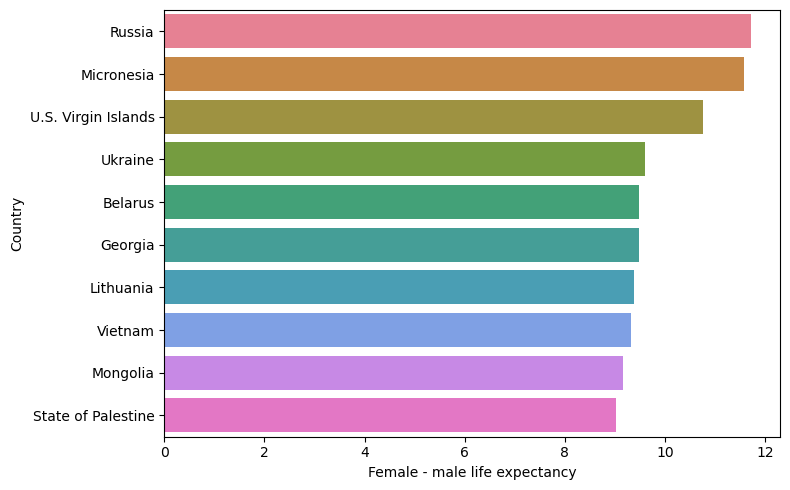

In [32]:
df["gap"] = (df["female"] - df["male"]).round(2)
gap10 = df.nlargest(10, "gap")
plt.figure(figsize=(8, 5))
sns.barplot(data=gap10, x="gap", y="Country", hue="Country", palette="husl", legend=False, dodge=False)
plt.xlabel("Female - male life expectancy")
plt.tight_layout()
plt.show()


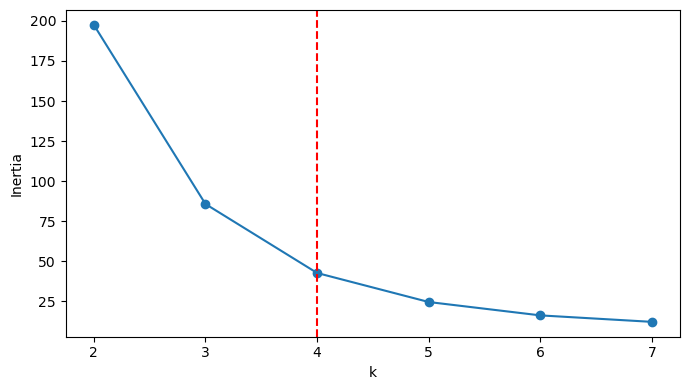

In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from kneed import KneeLocator

features = ["female", "male"]
x_scaled = StandardScaler().fit_transform(df[features])

inertias = []
for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(x_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(2, 8), inertias, marker="o")
plt.axvline(kl.elbow, color="red", linestyle="--")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.tight_layout()
plt.show()

In [34]:
kl = KneeLocator(range(2, 8), inertias, curve="convex", direction="decreasing")
print("Elbow k:", kl.elbow)

kmeans = KMeans(n_clusters=kl.elbow, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(x_scaled)

print("Silhouette:", silhouette_score(x_scaled, df["cluster"]))
df.groupby("cluster")[features].mean().round(2)

Elbow k: 4
Silhouette: 0.5348362704082944


,female,male
cluster,,
0,77.56,71.47
1,66.92,62.44
2,149.22,137.64
3,84.24,79.64


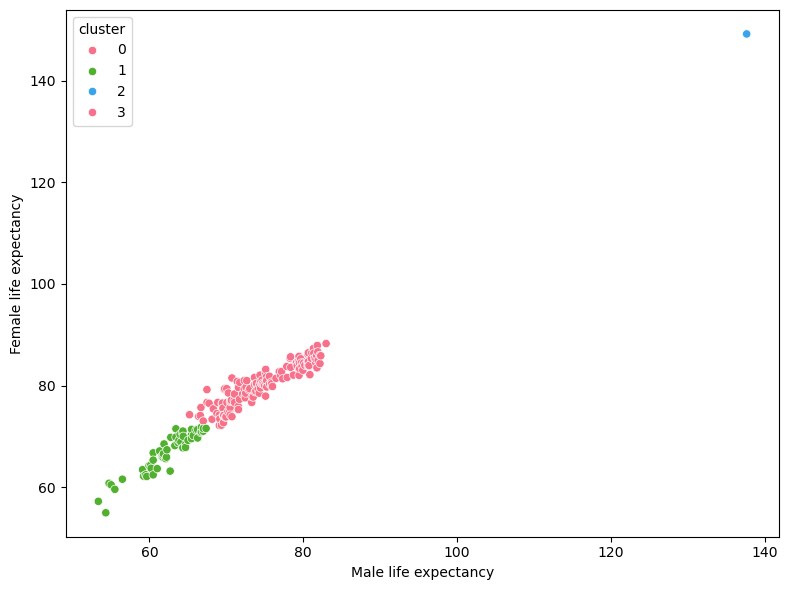

In [35]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="male", y="female", hue="cluster", palette="husl")
plt.xlabel("Male life expectancy")
plt.ylabel("Female life expectancy")
plt.tight_layout()
plt.show()

# Conclusion

I loaded country life expectancy for women and men and renamed the columns for easier use. The three life expectancy columns are almost the same measure, so their correlations are very high. I plotted the highest and lowest countries by overall life expectancy and the gap between female and male life expectancy. For clustering I used only female and male values, scaled them, and picked 4 clusters with KneeLocator. The silhouette score was about 0.53, which means the groups are reasonably well separated. The scatter plot shows low, middle and high life expectancy countries, with most points above the diagonal where women live longer than men.